## Import

In [ ]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import ops
from keras import Sequential
from keras.layers import LSTM, LayerNormalization, Dense, InputLayer
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping
from keras.metrics import (
    MeanAbsoluteError,
    RootMeanSquaredError,
    MeanAbsolutePercentageError
)

## Metadata

In [ ]:
# Read the file line by line
file_path = 'data/All_Residential.txt'

with open(file_path, 'r', encoding="utf-8") as f:
    lines = f.read().splitlines() # read line by line

In [ ]:
# Keep only the table (everything before the first "***")
end = next((i for i, line in enumerate(lines) if line.strip() == "***"), None) # find the index of element that start with ***
table_lines = [line for line in lines[:end] if line.strip()] # remove the empty space line and the line with
table_str = '\n'.join(table_lines) #convert list to string
table_io = io.StringIO(table_str) # convert to string
df = pd.read_fwf(table_io)
metadata = df.drop([0]) # drop the line below header

In [ ]:
# clean up metadata
metadata['HouseType_missing'] = metadata['HouseType'].isna().astype(int) # check for null
metadata['HouseType'] = metadata['HouseType'].fillna(metadata['HouseType'].mode()[0]) # fill in nans with most common house

metadata['Facing_missing'] = metadata['Facing'].isna().astype(int) # check for null
metadata['Facing'] = metadata['Facing'].fillna(metadata['Facing'].mode()[0]) # fill in nans with most common facing direction

metadata['Region_missing'] = metadata['Region'].isna().astype(int) # check for null
metadata['Region'] = metadata['Region'].fillna(metadata['Region'].mode()[0]) # fill in nans with most common region

metadata['HVAC_missing'] = metadata['HVAC'].isna().astype(int) # check for null
metadata['HVAC'] = metadata['HVAC'].fillna(metadata['HVAC'].mode()[0]) # fill in nans with most common HVAC

In [ ]:
metadata['House'] = metadata['House'].astype(int) # for merging with all residential data later
display(metadata)

,House,FirstReading,LastReading,Cover,HouseType,Facing,Region,RUs,EVs,SN,HVAC,HouseType_missing,Facing_missing,Region_missing,HVAC_missing
1,1,2012-06-01,2015-10-03,1.000,bungalow,South,YVR,1,NaN,1,FAGF + FPG + HP,0,0,0,0
2,2,2016-06-09,2019-11-20,0.994,duplex,North,YVR,0,NaN,2,"IFRHG + FPG, NAC",0,0,0,0
3,3,2015-01-27,2018-01-29,0.987,modern,South,YVR,2,NaN,NaN,"IFRHG + 1 BHE, NAC",0,0,0,0
4,4,2015-01-30,2018-01-29,0.995,character,West,YVR,1,NaN,NaN,"FAGF + IFRHG, NAC",0,0,0,0
5,5,2015-01-30,2018-01-29,0.995,modern,South,YVR,1,NaN,NaN,"IFRHG, NAC",0,0,0,0
6,6,2015-01-30,2018-01-29,0.997,apartment,SW,YVR,0,NaN,NaN,"BHE, NAC",0,0,0,0
7,7,2015-01-30,2018-01-29,0.997,apartment,South,YVR,NaN,NaN,NaN,"BHE, NAC",1,1,1,1
8,8,2015-02-21,2018-02-20,0.987,character,South,YVR,0,NaN,NaN,"FAGF, PAC",0,0,0,0
9,9,2015-05-01,2018-02-21,0.996,special,South,YVR,0,NaN,NaN,"IFRHG + FPG, NAC",0,0,0,0
10,10,2015-02-21,2018-02-20,0.995,special,South,YVR,0,NaN,NaN,"FAGF, NAC",0,0,0,0


## Holiday Data

In [ ]:
# read file
holidays = pd.read_csv('data/Holidays.csv')

In [ ]:
holidays['date'] = pd.to_datetime(holidays['date']) # convert string to datetime data type

In [ ]:
def first_weekday(year, month, weekday): # find that specific first day of the month based on the weekday index below
    """
    weekday:
        Monday=0
        Tuesday=1
        ...
        Sunday=6
    """
    d = pd.Timestamp(year, month, 1)

    while d.weekday() != weekday:
        d += Day(1)

    return d

#n, says which occurrence of that day you want: 1 for the first, 2 for the second, and so on.
def nth_weekday(year, month, weekday, n): # find that specific n-th day of the month based on the weekday index
    return first_weekday(year, month, weekday) + Week(n-1)

def last_weekday(year, month, weekday): # find that specific last day of the month based on the weekday index

    d = pd.Timestamp(year, month + 1, 1) - Day(1)

    while d.weekday() != weekday:
        d -= Day(1)

    return d

In [ ]:
def canadian_holidays(year):

    easter_sunday = pd.Timestamp(easter(year))

    dict_holidays = {
        "New Years":
            pd.Timestamp(year,1,1),
        "Good Friday":
            easter_sunday - Day(2),
        "Easter Monday":
            easter_sunday + Day(1),
        "Victoria Day":
            last_weekday(year,5,0) - Week(1),
        "Canada Day":
            pd.Timestamp(year,7,1),
        "Civic Day":
            first_weekday(year,8,0),
        "Labour Day":
            first_weekday(year,9,0),
        "Thanksgiving":
            nth_weekday(year,10,0,2),
        "Remembrance Day":
            pd.Timestamp(year,11,11),
        "Christmas Day":
            pd.Timestamp(year,12,25),
        "Boxing Day":
            pd.Timestamp(year,12,26),
        "Family Day":
            nth_weekday(year,2,0,3)
    }
    return dict_holidays

In [ ]:
def merge_holidays(df_in):

    years = range(
        df_in['date'].dt.year.min(),
        df_in['date'].dt.year.max()+1
    )

    holiday_rows = []

    for year in years:
        dict_holidays = canadian_holidays(year)
        for name, date in dict_holidays.items():
            holiday_rows.append({"date": date,"holiday": name})

    df_holidays = pd.DataFrame(holiday_rows)

    df_out = pd.merge(df_in, df_holidays, on='date', how='left')
    df_out['holiday'] = df_out['holiday'].fillna('None')

    return df_out

## Energy Household Data

In [ ]:
# Load energy consumption data for each house
energy_data = []
for i in range(1, 29):
    file_path = f'data/Residential_{i}.csv'
    df = pd.read_csv(file_path)
    df['date'] = pd.to_datetime(df['date'])

    # change hour to be 1 indexed instead of 0 indexed
    df['hour'] += 1

    # fix daylight savings shifts: Daylight saving starts in Mar and ends in Nov
    df['dst'] = 0
    # the start of daylight saving on the 2nd sunday of Mar => missing hour
    gap_mask = df['hour'].diff() == 2
    gap_mask &= df['date'].dt.month == 3
    gap_indices = list(np.where(gap_mask==True)[0])  # get indexes of those missings

    # the end of daylight saving on the 1st Sunday of Nov => repeated hour
    repeat_mask = df['hour'].diff() == 0
    repeat_mask &= df['date'].dt.month == 11
    repeat_indices = list(np.where(repeat_mask==True)[0]) # get indexes of those repeated hours

    # if that Residential data has only the end of daylight saving but not the start of daylight saving
    if (len(repeat_indices) == 1) and (len(gap_indices) == 0):
        gap_indices.insert(0,0) # in the current dataset, although there is no start of daylight saving in Mar, the current start date and time is already in affective of Mar logics

    # if the dataset has Mar start of daylight saving but not the end of it
    if (len(gap_indices) == 1) and (len(repeat_indices) == 0):
        repeat_indices.append(len(df)) # the November transition is missing, perhaps because the dataset ends before November so from the index of the start of Daylight saving until the last index in that data is still in Mar logics. Anything outside that is Nov logics

    # speaking of the index order, if the first Nov index is lesser than the first Mar index, that means the data start with Nov first
    if repeat_indices[0] < gap_indices[0]:
        gap_indices.insert(0,0) # that means before reaching the first Nov, it has already been following the Mar logic since the first index

    # speaking of the index order, if the last Nov index is lesser than the last Mar index, that means the data end with Mar
    if repeat_indices[-1] < gap_indices[-1]:
        repeat_indices.append(len(df)) # that means from the start of the last Nov until the last indexes, it still follows Nov logics

    # for each DST period (start -> stop): shift hours back to standard time and flag dst = 1
    for start, stop in zip(gap_indices, repeat_indices): # pair start and last index with the if conditions above
        df.loc[start:stop-1, 'hour'] -= 1 # that missing hour is handled by substracting everything by 1 and then everything is converted to the standard time so no hour is using Daylight saving standard
        df.loc[start:stop-1, 'dst'] = 1

    # fix hours that are 0
    zero_mask = df['hour'] == 0
    df.loc[zero_mask, 'hour'] = 24 # find hours that are 0 after the subtraction above and assign it to 24h
    df.loc[zero_mask, 'date'] -= pd.Timedelta(days=1) # need to adjust the date for those hours

    # get rid of duplicate rows
    df = df.drop_duplicates()

    # clean up data
    df['datetime'] = pd.to_datetime(df['date'])+pd.to_timedelta(df['hour']-1, unit='h') # get the date time from data
    df = df.set_index('datetime') # make datetime as the index of the dataframe
    df = df.reindex(pd.date_range(df.index.min(), df.index.max(), freq='h')) # build a complete hour between the start date and end date. If there is any missing hour or day, it will assign null to the daate and hour fields
    df['date'] = df.index.strftime("%Y-%m-%d") # reassign the date in case there is any missing date
    df['hour'] = df.index.hour+1 # reassign the hour in case there is any missing hour and +1 is added so that the hour start with 1 rather than 0
    df = df.reset_index(drop=True)

    # handle null value for energy_kWh field
    df['kWh_missing'] = df['energy_kWh'].isna().astype(int)
    column_list = ['energy_kWh']

    for column in column_list:
        selected_energy_feature = df[column]

        # average of the hour before and after
        energy_feature = (selected_energy_feature.shift(1) + selected_energy_feature.shift(-1)) / 2

        # if energy_feature is still null, average of the same hour one day before and after
        energy_feature = energy_feature.fillna((selected_energy_feature.shift(24) + selected_energy_feature.shift(-24)) / 2)

        # if energy_feature is still null, copy the same hour from the day before
        energy_feature = energy_feature.fillna(selected_energy_feature.shift(24))

        # if energy_feature is still null, copy the same hour from the day after
        energy_feature = energy_feature.fillna(selected_energy_feature.shift(-24))

        # write back: only fill the original NaN rows
        df[column] = selected_energy_feature.fillna(energy_feature.round(3))

    df['House'] = i
    df['date'] = pd.to_datetime(df['date'])

    energy_data.append(df)

energy_data = pd.concat(energy_data, ignore_index=True)

# Convert House column to int64
energy_data['House'] = energy_data['House'].astype(int)

# set a minimum baseline energy usage where there are hours with 0
energy_data.loc[energy_data['energy_kWh']==0,'energy_kWh'] = energy_data[energy_data['energy_kWh'] > 0]['energy_kWh'].min()

In [ ]:
# Merge energy data with metadata
merged_residential_data = pd.merge(energy_data, metadata, on='House', how='left')

In [ ]:
display(merged_residential_data)

,date,hour,energy_kWh,dst,kWh_missing,House,FirstReading,LastReading,Cover,HouseType,Facing,Region,RUs,EVs,SN,HVAC,HouseType_missing,Facing_missing,Region_missing,HVAC_missing
0,2012-06-01,1,1.011,1.0,0,1,2012-06-01,2015-10-03,1.000,bungalow,South,YVR,1,NaN,1,FAGF + FPG + HP,0,0,0,0
1,2012-06-01,2,0.451,1.0,0,1,2012-06-01,2015-10-03,1.000,bungalow,South,YVR,1,NaN,1,FAGF + FPG + HP,0,0,0,0
2,2012-06-01,3,0.505,1.0,0,1,2012-06-01,2015-10-03,1.000,bungalow,South,YVR,1,NaN,1,FAGF + FPG + HP,0,0,0,0
3,2012-06-01,4,0.441,1.0,0,1,2012-06-01,2015-10-03,1.000,bungalow,South,YVR,1,NaN,1,FAGF + FPG + HP,0,0,0,0
4,2012-06-01,5,0.468,1.0,0,1,2012-06-01,2015-10-03,1.000,bungalow,South,YVR,1,NaN,1,FAGF + FPG + HP,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
616075,2020-05-19,19,3.060,1.0,0,28,2018-08-01,2020-05-19,0.998,special,North,YVR,0,NaN,NaN,"FAGF + 1 FPE + 2 FPG, NAC",0,0,0,0
616076,2020-05-19,20,2.940,1.0,0,28,2018-08-01,2020-05-19,0.998,special,North,YVR,0,NaN,NaN,"FAGF + 1 FPE + 2 FPG, NAC",0,0,0,0
616077,2020-05-19,21,1.970,1.0,0,28,2018-08-01,2020-05-19,0.998,special,North,YVR,0,NaN,NaN,"FAGF + 1 FPE + 2 FPG, NAC",0,0,0,0
616078,2020-05-19,22,2.130,1.0,0,28,2018-08-01,2020-05-19,0.998,special,North,YVR,0,NaN,NaN,"FAGF + 1 FPE + 2 FPG, NAC",0,0,0,0


## Weather Data

In [ ]:
# Load YVR weather data
weather_yvr = pd.read_csv('data/Weather_YVR.csv')

In [ ]:
# clean up YVR data
weather_yvr['datetime'] = pd.to_datetime(weather_yvr['date'])+pd.to_timedelta(weather_yvr['hour']-1, unit='h') # get the date time from data
weather_yvr = weather_yvr.set_index('datetime') # make datetime as the index of the dataframe
weather_yvr = weather_yvr.reindex(pd.date_range(weather_yvr.index.min(), weather_yvr.index.max(), freq='h')) # build a complete hour between the start date and end date. If there is any missing hour or day, it will assign null to the daate and hour fields
weather_yvr['date'] = weather_yvr.index.strftime("%Y-%m-%d") # reassign the date in case there is any missing date
weather_yvr['hour'] = weather_yvr.index.hour+1 # reassign the hour in case there is any missing hour and +1 is added so that the hour start with 1 rather than 0
weather_yvr = weather_yvr.reset_index(drop=True)
weather_yvr['Region']='YVR'

In [ ]:
# fill in the nans
weather_yvr['temp_missing'] = weather_yvr['temperature'].isna().astype(int)
weather_yvr['humid_missing'] = weather_yvr['humidity'].isna().astype(int)
weather_yvr['press_missing'] = weather_yvr['pressure'].isna().astype(int)

column_list = ['temperature', 'humidity', 'pressure']

for column in column_list:
    selected_weather_feature = weather_yvr[column]

    # average of the hour before and after
    weather_feature = (selected_weather_feature.shift(1) + selected_weather_feature.shift(-1)) / 2

    # if weather_feature is still null, average of the same hour one day before and after
    weather_feature = weather_feature.fillna((selected_weather_feature.shift(24) + selected_weather_feature.shift(-24)) / 2)

    # if weather_feature is still null, copy the same hour from the day before
    weather_feature = weather_feature.fillna(selected_weather_feature)

    # if weather_feature is still null, copy the same hour from the day after
    weather_feature = weather_feature.fillna(selected_weather_feature.shift(-24))

    # write back: only the original NaN rows get a new value
    weather_yvr[column] = selected_weather_feature.fillna(weather_feature.round(2))

In [ ]:
weather_yvr['weather_missing'] = weather_yvr['weather'].isna().astype(int)
weather_yvr['weather'] = weather_yvr['weather'].ffill() # fill the current null with the previous non-null value

In [ ]:
display(weather_yvr)

,date,hour,temperature,humidity,pressure,weather,Region,temp_missing,humid_missing,press_missing,weather_missing
0,2012-01-01,1,2.4,74.0,102.63,Cloudy,YVR,0,0,0,0
1,2012-01-01,2,2.8,69.0,102.62,Cloudy,YVR,0,0,0,0
2,2012-01-01,3,2.8,69.0,102.69,Cloudy,YVR,0,0,0,0
3,2012-01-01,4,2.6,71.0,102.75,Cloudy,YVR,0,0,0,0
4,2012-01-01,5,2.8,69.0,102.78,Cloudy,YVR,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
73339,2020-05-13,20,15.0,68.0,101.10,Mostly Cloudy,YVR,0,0,0,0
73340,2020-05-13,21,13.4,78.0,101.14,Mostly Cloudy,YVR,0,0,0,1
73341,2020-05-13,22,13.6,73.0,101.19,Mostly Cloudy,YVR,0,0,0,1
73342,2020-05-13,23,12.7,89.0,101.21,Mainly Clear,YVR,0,0,0,0


In [ ]:
# Load WYJ weather data
weather_wyj = pd.read_csv('data/Weather_WYJ.csv')

In [ ]:
# clean up WYJ data
weather_wyj['datetime'] = pd.to_datetime(weather_wyj['date'])+pd.to_timedelta(weather_wyj['hour']-1, unit='h') # get the date time from data
weather_wyj = weather_wyj.set_index('datetime') # make datetime as the index of the dataframe
weather_wyj = weather_wyj.reindex(pd.date_range(weather_wyj.index.min(), weather_wyj.index.max(), freq='h')) # build a complete hour between the start date and end date. If there is any missing hour or day, it will assign null to the daate and hour fields
weather_wyj['date'] = weather_wyj.index.strftime("%Y-%m-%d") # reassign the date in case there is any missing date
weather_wyj['hour'] = weather_wyj.index.hour+1 # reassign the hour in case there is any missing hour and +1 is added so that the hour start with 1 rather than 0
weather_wyj = weather_wyj.reset_index(drop=True)
weather_wyj['Region']='WYJ'

In [ ]:
# fill in the nans
weather_wyj['temp_missing'] = weather_wyj['temperature'].isna().astype(int)
weather_wyj['humid_missing'] = weather_wyj['humidity'].isna().astype(int)
weather_wyj['press_missing'] = weather_wyj['pressure'].isna().astype(int)

column_list = ['temperature', 'humidity', 'pressure']

for column in column_list:
    selected_weather_feature = weather_wyj[column]

    # average of the hour before and after
    weather_feature = (selected_weather_feature.shift(1) + selected_weather_feature.shift(-1)) / 2

    # if weather_feature is still null, average of the same hour one day before and after
    weather_feature = weather_feature.fillna((selected_weather_feature.shift(24) + selected_weather_feature.shift(-24)) / 2)

    # if weather_feature is still null, copy the same hour from the day before
    weather_feature = weather_feature.fillna(selected_weather_feature)

    # if weather_feature is still null, copy the same hour from the day after
    weather_feature = weather_feature.fillna(selected_weather_feature.shift(-24))

    # write back: only the original NaN rows get a new value
    weather_wyj[column] = selected_weather_feature.fillna(weather_feature.round(2))

In [ ]:
weather_wyj['weather_missing'] = weather_wyj['weather'].isna().astype(int)
weather_wyj['weather'] = weather_wyj['weather'].ffill() # fill the current null with the previous non-null value

"""
    I notice that weather_wyj has null for all cells in column: temperature, humidity, and pressure.
    So maybe we can just copy from weather_yvr instead
"""

# use weather data from yvr region
lookup = weather_yvr.set_index(['date', 'hour'])['weather']
weather_wyj['weather'] = pd.Series(list(zip(weather_wyj['date'], weather_wyj['hour']))).map(lookup)

In [ ]:
display(weather_wyj)

,date,hour,temperature,humidity,pressure,weather,Region,temp_missing,humid_missing,press_missing,weather_missing
0,2015-01-01,1,0.7,88.0,102.31,Clear,WYJ,0,0,0,1
1,2015-01-01,2,1.0,88.0,102.26,Clear,WYJ,0,0,0,1
2,2015-01-01,3,0.7,90.0,102.22,Clear,WYJ,0,0,0,1
3,2015-01-01,4,0.6,90.0,102.18,Clear,WYJ,0,0,0,1
4,2015-01-01,5,-0.4,91.0,102.11,Clear,WYJ,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...
43819,2019-12-31,20,11.5,98.0,99.37,Cloudy,WYJ,0,0,0,1
43820,2019-12-31,21,11.1,95.0,99.35,Cloudy,WYJ,0,0,0,1
43821,2019-12-31,22,10.8,94.0,99.34,Cloudy,WYJ,0,0,0,1
43822,2019-12-31,23,10.7,92.0,99.38,Mostly Cloudy,WYJ,0,0,0,1


In [ ]:
weather_data = pd.concat([weather_wyj, weather_yvr])
display(weather_data)

,date,hour,temperature,humidity,pressure,weather,Region,temp_missing,humid_missing,press_missing,weather_missing
0,2015-01-01,1,0.7,88.0,102.31,Clear,WYJ,0,0,0,1
1,2015-01-01,2,1.0,88.0,102.26,Clear,WYJ,0,0,0,1
2,2015-01-01,3,0.7,90.0,102.22,Clear,WYJ,0,0,0,1
3,2015-01-01,4,0.6,90.0,102.18,Clear,WYJ,0,0,0,1
4,2015-01-01,5,-0.4,91.0,102.11,Clear,WYJ,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...
73339,2020-05-13,20,15.0,68.0,101.10,Mostly Cloudy,YVR,0,0,0,0
73340,2020-05-13,21,13.4,78.0,101.14,Mostly Cloudy,YVR,0,0,0,1
73341,2020-05-13,22,13.6,73.0,101.19,Mostly Cloudy,YVR,0,0,0,1
73342,2020-05-13,23,12.7,89.0,101.21,Mainly Clear,YVR,0,0,0,0


## Building RNN

In [ ]:
WINDOW_SIZE = 24
layerLSTM1 = 64
layerLSTM2 = 64
NUM_LAYERS = 2
DROPOUT = 0.20
BATCH_SIZE = 256
EPOCHS = 50
PATIENCE = 10
LEARNING_RATE = 0.001
SEED = 42
VERBOSE = 2  # 0 = silent, 1 = progress bar, 2 = one line per epoch

keras.utils.set_random_seed(SEED)

In [ ]:
df = merged_residential_data.copy()
df = df.sort_values(["House", "date", "hour"]).reset_index(drop=True)

print("Rows:", len(df), "| Houses:", df["House"].nunique())

Rows: 616080 | Houses: 28


In [ ]:
# Six lists: X contains lookback windows; y contains next-hour targets.
X_train, y_train = [], []
X_val, y_val = [], []
X_test, y_test = [], []

for house_id, house in df.groupby("House", sort=False):
    values = house["energy_kWh"].to_numpy(dtype=np.float32)
    n = len(values)

    # 70% train, 15% validation, 15% test, in time order per house.
    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    if train_end <= WINDOW_SIZE or val_end <= train_end or val_end >= n:
        continue

    # Each X is the previous WINDOW_SIZE hours; y is the next hour.
    for t in range(WINDOW_SIZE, n):
        X = values[t - WINDOW_SIZE:t].reshape(WINDOW_SIZE, 1)
        y = values[t]

        if not np.isfinite(X).all() or not np.isfinite(y):
            continue

        if t < train_end:
            X_train.append(X)
            y_train.append(y)
        elif t < val_end:
            X_val.append(X)
            y_val.append(y)
        else:
            X_test.append(X)
            y_test.append(y)

# Convert lists to the array shapes Keras expects.
X_train = np.asarray(X_train, dtype=np.float32)
y_train = np.asarray(y_train, dtype=np.float32)
X_val = np.asarray(X_val, dtype=np.float32)
y_val = np.asarray(y_val, dtype=np.float32)
X_test = np.asarray(X_test, dtype=np.float32)
y_test = np.asarray(y_test, dtype=np.float32)

for name, X, y in [("Train", X_train, y_train),
                   ("Validation", X_val, y_val),
                   ("Test", X_test, y_test)]:
    if len(X) == 0:
        raise ValueError(f"No valid {name.lower()} windows were created.")
    print(f"{name}: X = {X.shape}, y = {y.shape}")

Train: X = (429115, 24, 1), y = (429115,)
Validation: X = (92249, 24, 1), y = (92249,)
Test: X = (92272, 24, 1), y = (92272,)


In [ ]:
@keras.saving.register_keras_serializable(package="Custom")
def smape(y_true, y_pred):
    y_true = ops.cast(ops.reshape(y_true, (-1,)), "float32")
    y_pred = ops.cast(ops.reshape(y_pred, (-1,)), "float32")
    numerator = ops.abs(y_true - y_pred)
    denominator = ops.abs(y_true) + ops.abs(y_pred)
    # 0% when actual=prediction=0; bounded near 200% otherwise.
    return 200.0 * numerator / ops.maximum(denominator, 1e-7)

In [ ]:
layerDense = 32

model = Sequential()
model.add(InputLayer((WINDOW_SIZE, 1)))
model.add(LSTM(layerLSTM1, dropout=DROPOUT, return_sequences=False))
# model.add(LSTM(layerLSTM2, dropout=DROPOUT, return_sequences=False, kernel_initializer="glorot_uniform", recurrent_initializer="orthogonal"))
model.add(LayerNormalization())
model.add(Dense(layerDense, 'relu', kernel_initializer="he_normal"))
model.add(Dense(1, 'linear'))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization             │ (None, 64)             │           128 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,137 (74.75 KB)

 Trainable params: 19,137 (74.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss="mse",
    metrics=[
        MeanAbsoluteError(name="mae"),
        RootMeanSquaredError(name="rmse"),
        MeanAbsolutePercentageError(name="mape"),
        smape,
    ],
)

early_stopping = EarlyStopping(
    monitor="val_loss", patience=PATIENCE, restore_best_weights=True
)


In [ ]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping],
    verbose=VERBOSE,
)


best_epoch = int(np.argmin(history.history["val_loss"]) + 1)
print(f"Best epoch: {best_epoch}")
print(f"Best validation MSE (standardized): {min(history.history['val_loss']):.5f}")

Epoch 1/50
1677/1677 - 187s - 112ms/step - loss: 0.4000 - mae: 0.3705 - mape: 84.1158 - rmse: 0.6325 - smape: 46.1785 - val_loss: 0.3065 - val_mae: 0.3162 - val_mape: 49.8269 - val_rmse: 0.5536 - val_smape: 62.7829
Epoch 2/50
1677/1677 - 186s - 111ms/step - loss: 0.3839 - mae: 0.3596 - mape: 80.7416 - rmse: 0.6196 - smape: 44.7450 - val_loss: 0.3035 - val_mae: 0.3057 - val_mape: 44.1842 - val_rmse: 0.5509 - val_smape: 53.6451
Epoch 3/50
1677/1677 - 190s - 113ms/step - loss: 0.3777 - mae: 0.3557 - mape: 79.4168 - rmse: 0.6146 - smape: 43.9102 - val_loss: 0.2782 - val_mae: 0.2656 - val_mape: 37.2169 - val_rmse: 0.5275 - val_smape: 33.6358
Epoch 4/50
1677/1677 - 187s - 112ms/step - loss: 0.3753 - mae: 0.3542 - mape: 78.8701 - rmse: 0.6126 - smape: 43.5888 - val_loss: 0.2889 - val_mae: 0.2827 - val_mape: 37.6339 - val_rmse: 0.5375 - val_smape: 42.1084
Epoch 5/50
1677/1677 - 187s - 111ms/step - loss: 0.3745 - mae: 0.3531 - mape: 78.5587 - rmse: 0.6120 - smape: 43.1750 - val_loss: 0.2634 - v

In [37]:
results = model.evaluate(X_test, y_test, batch_size=BATCH_SIZE,
                         verbose=0, return_dict=True)
print("\nTest results (raw kWh; no inverse scaling):")
print(f"MSE:   {results['loss']:.5f} kWh^2")
print(f"MAE:   {results['mae']:.5f} kWh")
print(f"RMSE:  {results['rmse']:.5f} kWh")
print(f"MAPE:  {results['mape']:.2f}%")
print(f"sMAPE: {results['smape']:.2f}%")


Test results (raw kWh; no inverse scaling):
MSE:   0.37458 kWh^2
MAE:   0.30746 kWh
RMSE:  0.61203 kWh
MAPE:  36.60%
sMAPE: 31.17%


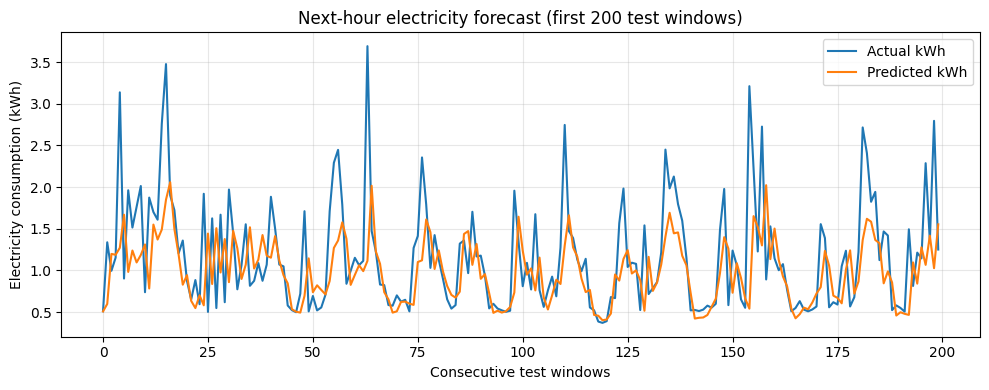

In [35]:
predictions = model.predict(X_test, batch_size=BATCH_SIZE,
                            verbose=0).reshape(-1)
actual = y_test.reshape(-1)

n_show = min(200, len(actual))
plt.figure(figsize=(10, 4))
plt.plot(actual[:n_show], label="Actual kWh")
plt.plot(predictions[:n_show], label="Predicted kWh")
plt.xlabel("Consecutive test windows")
plt.ylabel("Electricity consumption (kWh)")
plt.title("Next-hour electricity forecast (first 200 test windows)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()